In [5]:
import matplotlib.pyplot as plt
import numpy as np
import hdbscan

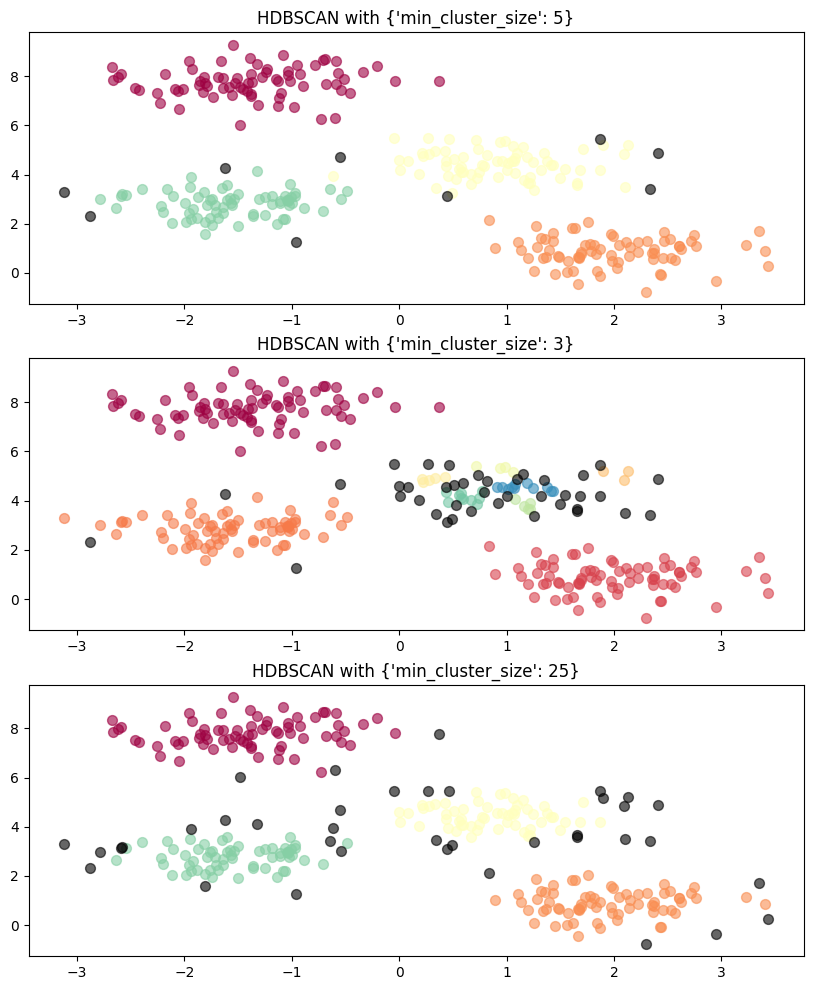

In [7]:
	PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
	fig, axes = plt.subplots(3, 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    hdb = hdbscan.HDBSCAN(**param).fit(X)
	    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

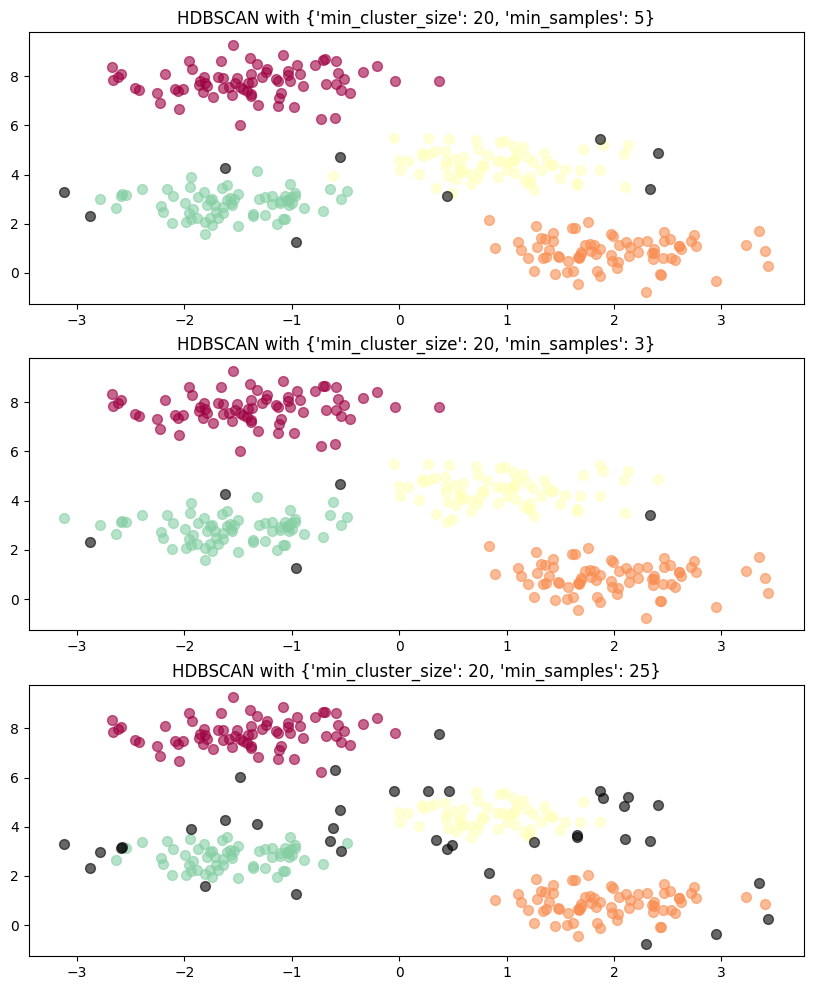

In [8]:
	PARAM = (
	    {"min_cluster_size": 20, "min_samples": 5},
	    {"min_cluster_size": 20, "min_samples": 3},
	    {"min_cluster_size": 20, "min_samples": 25},
	)
	fig, axes = plt.subplots(3, 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    hdb = hdbscan.HDBSCAN(**param).fit(X)
	    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])

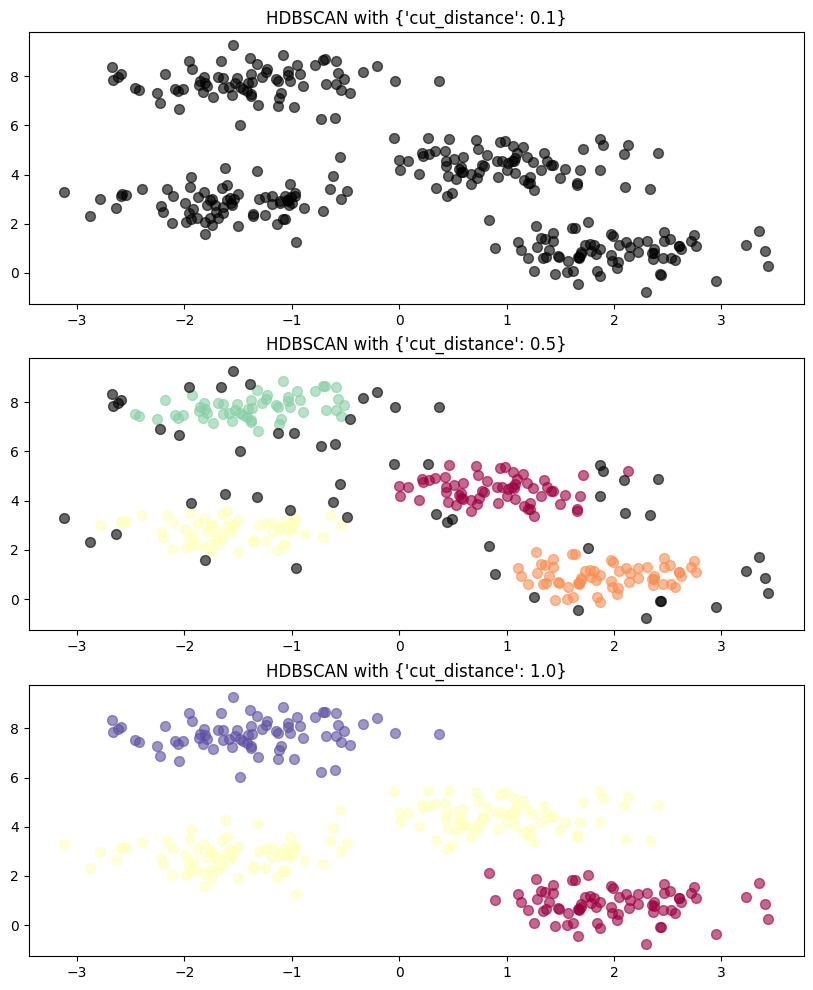

In [9]:
	PARAM = (
	    {"cut_distance": 0.1},
	    {"cut_distance": 0.5},
	    {"cut_distance": 1.0},
	)
	hdb = hdbscan.HDBSCAN().fit(X)
	fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
	for i, param in enumerate(PARAM):
	    labels = hdb.dbscan_clustering(**param)
	    plot(X, labels, hdb.probabilities_, param, ax=axes[i])

In [10]:
	from sklearn.metrics import silhouette_score

	# Compute Silhouette Score for HDBSCAN clustering results
	sil_score = silhouette_score(X, hdb.labels_)
	print(f"Silhouette Score: {sil_score}")

Silhouette Score: 0.6355533260603515


In [11]:
	from sklearn.metrics import davies_bouldin_score

	# Compute Davies-Bouldin Index for HDBSCAN clustering results
	dbi_score = davies_bouldin_score(X, hdb.labels_)
	print(f"Davies-Bouldin Index: {dbi_score}")

Davies-Bouldin Index: 1.5281455967243376


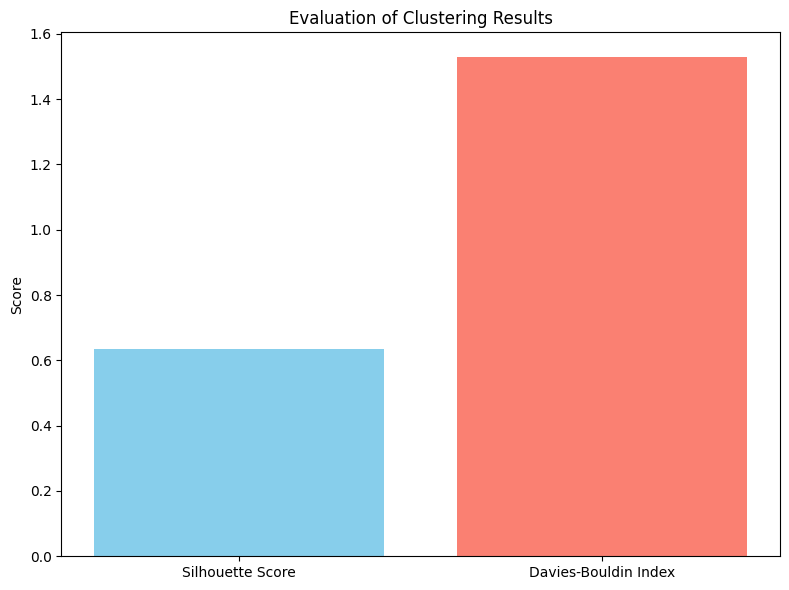

In [12]:
	# For example, if we want to compare DBI and Silhouette Score for several experiments
	scores = {
	    "Silhouette Score": sil_score,
	    "Davies-Bouldin Index": dbi_score
	}

	# Plot the evaluation results
	fig, ax = plt.subplots(figsize=(8, 6))
	ax.bar(scores.keys(), scores.values(), color=['skyblue', 'salmon'])
	ax.set_title("Evaluation of Clustering Results")
	ax.set_ylabel("Score")
	plt.tight_layout()
	plt.show()